In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, silhouette_score

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
import pandas as pd

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nChurn Distribution:")
print(df['Churn'].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000



Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate Rows: 0

Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [6]:
# Remove unnecessary customer ID column
df.drop('customerID', axis=1, inplace=True)

# Convert TotalCharges to numeric
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove rows containing missing values
df.dropna(inplace=True)

# Check duplicates
print("\nDuplicate rows:", df.duplicated().sum())

# Final dataset details
print("\nDataset shape after cleaning:", df.shape)
print("\nMissing values after cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Duplicate rows: 22

Dataset shape after cleaning: (7032, 20)

Missing values after cleaning:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
Total

In [7]:
df.drop_duplicates(inplace=True)

print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Dataset shape after removing duplicates: (7010, 20)
Remaining duplicates: 0


Churn
No     5153
Yes    1857
Name: count, dtype: int64


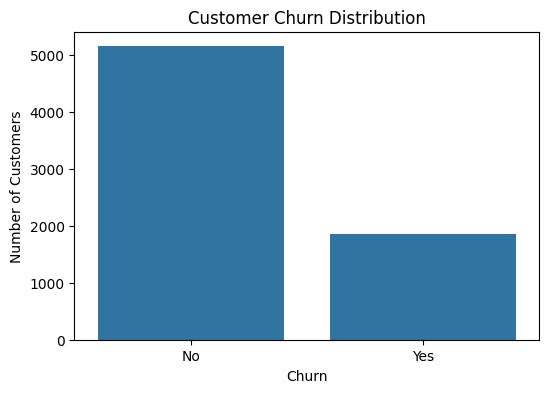

In [8]:
# Count customers in each churn category
print(df['Churn'].value_counts())

# Visualize churn distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.show()

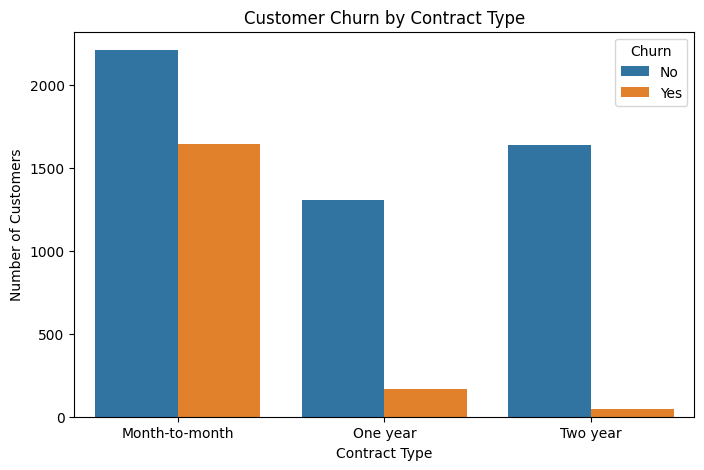

In [9]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Contract', hue='Churn')

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.show()

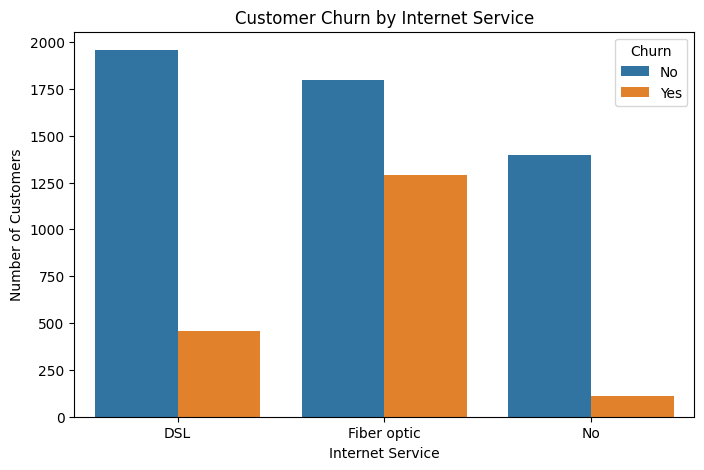

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='InternetService', hue='Churn')

plt.title('Customer Churn by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Number of Customers')
plt.show()

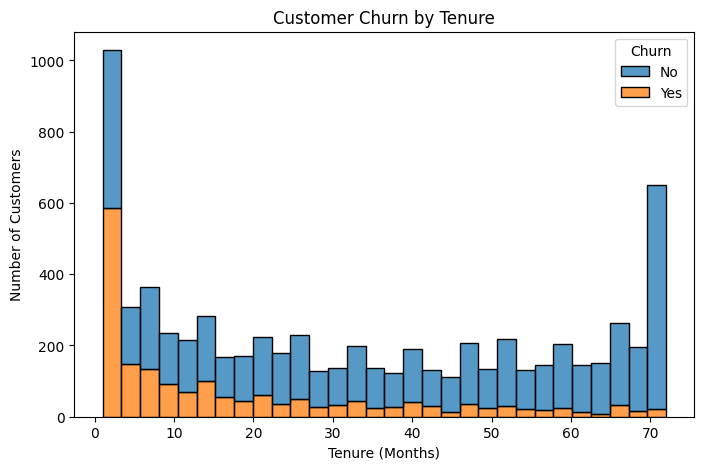

In [11]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='tenure', hue='Churn',
             bins=30, multiple='stack')

plt.title('Customer Churn by Tenure')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')
plt.show()

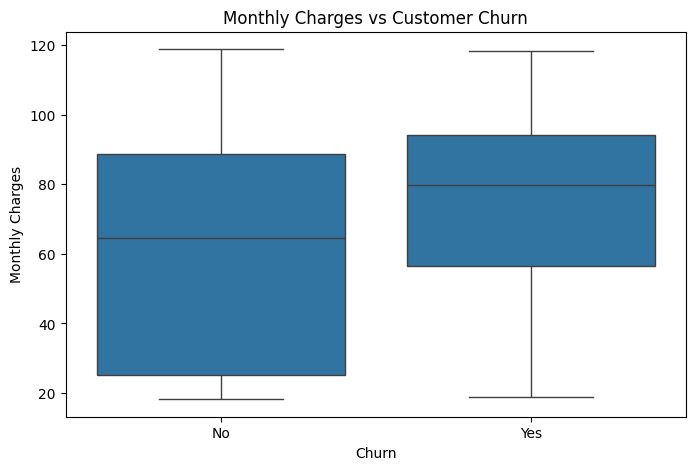

In [12]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Churn', y='MonthlyCharges')

plt.title('Monthly Charges vs Customer Churn')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')
plt.show()

In [13]:
# Create a copy for machine learning
data = df.copy()

# Convert categorical columns into numerical values
le = LabelEncoder()

for column in data.select_dtypes(include='object').columns:
    data[column] = le.fit_transform(data[column])

print("Categorical columns encoded successfully!")

display(data.head())

Categorical columns encoded successfully!


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


In [14]:
# Separate input features and target variable
X = data.drop('Churn', axis=1)
y = data['Churn']

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (5608, 19)
Testing data shape: (1402, 19)


In [15]:
# Create Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train, y_train)

# Make predictions
y_pred = lr_model.predict(X_test)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


Logistic Regression Evaluation
Accuracy: 0.8202567760342369
Precision: 0.6153846153846154
Recall: 0.573208722741433
F1 Score: 0.5935483870967742

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.89      0.88      1081
           1       0.62      0.57      0.59       321

    accuracy                           0.82      1402
   macro avg       0.75      0.73      0.74      1402
weighted avg       0.82      0.82      0.82      1402



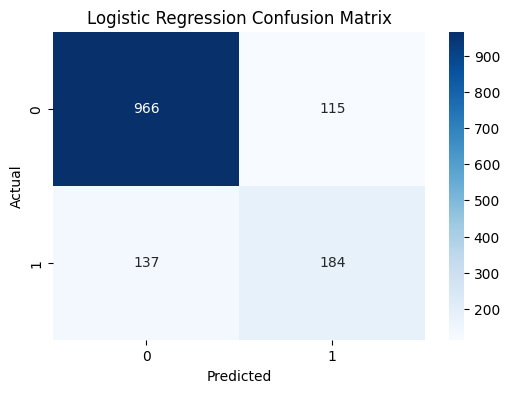

In [16]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

print("Logistic Regression Evaluation")

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [17]:
# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_pred = rf_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


Random Forest Evaluation
Accuracy: 0.8009985734664765
Precision: 0.5734265734265734
Recall: 0.5109034267912772
F1 Score: 0.5403624382207578

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.89      0.87      1081
           1       0.57      0.51      0.54       321

    accuracy                           0.80      1402
   macro avg       0.72      0.70      0.71      1402
weighted avg       0.79      0.80      0.80      1402



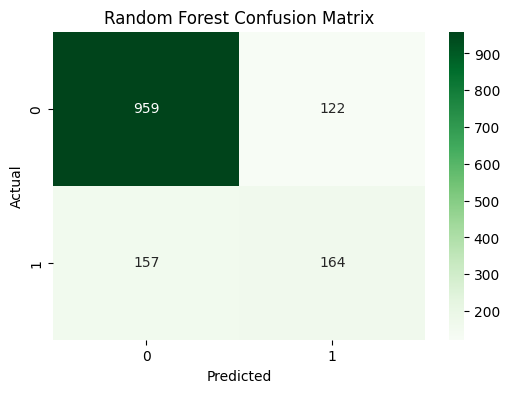

In [18]:
from sklearn.metrics import precision_score, recall_score, f1_score

print("Random Forest Evaluation")

print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

# Confusion Matrix
cm_rf = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens')

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [19]:
# Select features for clustering
cluster_data = data[['tenure', 'MonthlyCharges', 'TotalCharges']]

# Scale the features
scaler = StandardScaler()
scaled_data = scaler.fit_transform(cluster_data)

# Apply K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df['CustomerSegment'] = kmeans.fit_predict(scaled_data)

print("K-Means clustering completed!")
print("\nCustomer Segment Distribution:")
print(df['CustomerSegment'].value_counts())

K-Means clustering completed!

Customer Segment Distribution:
CustomerSegment
2    2678
1    2194
0    2138
Name: count, dtype: int64


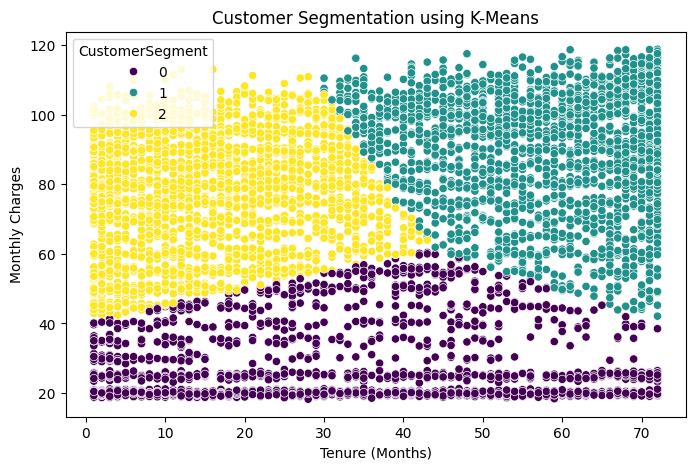

In [20]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='tenure',
    y='MonthlyCharges',
    hue='CustomerSegment',
    palette='viridis'
)

plt.title('Customer Segmentation using K-Means')
plt.xlabel('Tenure (Months)')
plt.ylabel('Monthly Charges')
plt.show()

In [21]:
score = silhouette_score(scaled_data, df['CustomerSegment'])

print("K-Means Silhouette Score:", score)

K-Means Silhouette Score: 0.4517056796563236


Top 10 Important Features:


,Feature,Importance
18,TotalCharges,0.186451
17,MonthlyCharges,0.177753
4,tenure,0.156308
14,Contract,0.081180
16,PaymentMethod,0.051920
8,OnlineSecurity,0.048310
11,TechSupport,0.044467
0,gender,0.028672
9,OnlineBackup,0.026753
15,PaperlessBilling,0.025521


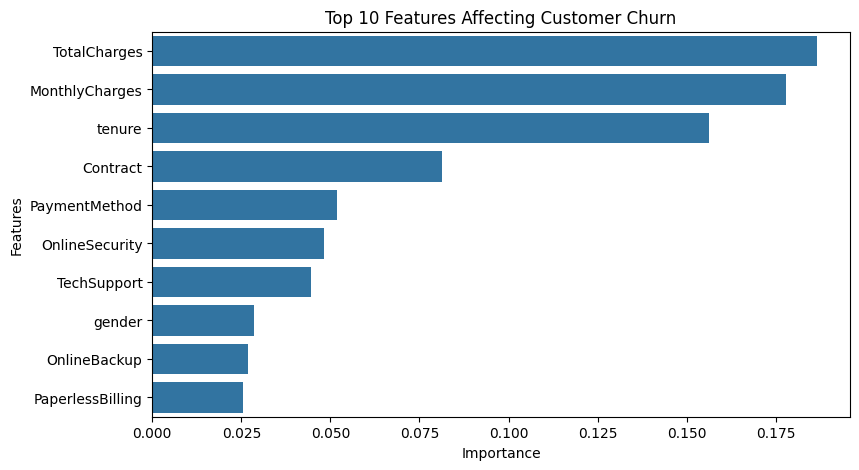

In [22]:
# Get feature importance
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

# Sort features by importance
importance = importance.sort_values(
    by='Importance', ascending=False
)

print("Top 10 Important Features:")
display(importance.head(10))

# Visualize feature importance
plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Features Affecting Customer Churn')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.show()

In [23]:
print("CUSTOMER CHURN ANALYSIS AND PREDICTION")
print("--------------------------------------")

print("Total Customers:", len(df))
print("Total Features:", data.shape[1] - 1)

print("\nModel Performance:")
print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred))

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred))

print("\nK-Means Silhouette Score:", score)

print("\nTop 3 Important Features:")
display(importance.head(3))

print("\nPROJECT COMPLETED SUCCESSFULLY!")

CUSTOMER CHURN ANALYSIS AND PREDICTION
--------------------------------------
Total Customers: 7010
Total Features: 19

Model Performance:
Logistic Regression Accuracy: 0.8202567760342369
Random Forest Accuracy: 0.8009985734664765

K-Means Silhouette Score: 0.4517056796563236

Top 3 Important Features:


,Feature,Importance
18,TotalCharges,0.186451
17,MonthlyCharges,0.177753
4,tenure,0.156308



PROJECT COMPLETED SUCCESSFULLY!
